
# Expense Analyzer: A Python-Based Personal Expense Tracking and Data Analysis System

## 1. Problem Statement

Managing personal expenses manually makes it difficult to identify spending patterns and understand how money is distributed across different categories. This project uses Python data analysis libraries to organize expense records and generate useful spending summaries.

## 2. Objectives

- Analyze expense records using NumPy and Pandas.
- Calculate total, average, median, maximum, and minimum expenses.
- Summarize spending by category.
- Analyze monthly expenditure.
- Visualize spending patterns using Matplotlib and Seaborn.
- Support a complete expense management application with SQLite persistence, a terminal interface, a Flask dashboard, and summary report exports.

## 3. Project Scope

The notebook focuses on data loading, cleaning, statistical analysis, category-wise aggregation, monthly analysis, and visualization. The complete project also includes SQLite persistence, a terminal application, and a Flask web dashboard. This notebook focuses on CSV-based data analysis.

## 4. Technologies Used

- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## 5. Dataset Description

The primary dataset is expenses.csv in the project directory. It contains 10 transactions with IDs, dates, categories, descriptions, and amounts. The notebook validates and analyzes this unified dataset without modifying the source CSV.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Seaborn version:", sns.__version__)


All libraries imported successfully.
NumPy version: 2.5.4
Pandas version: 3.0.6
Seaborn version: 0.13.2


In [2]:

# Locate the existing project CSV
possible_paths = [
    Path.cwd() / "expenses.csv",
    Path.cwd().parent / "expenses.csv"
]

EXPENSE_FILE = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if EXPENSE_FILE is None:
    raise FileNotFoundError(
        "expenses.csv not found. Check the notebook's working directory."
    )

# Read the CSV into a Pandas DataFrame
df = pd.read_csv(EXPENSE_FILE)

print("Dataset loaded successfully!")
print("File location:", EXPENSE_FILE.resolve())
print("Dataset dimensions:", df.shape)

display(df)


Dataset loaded successfully!
File location: C:\Users\santh\OneDrive\Desktop\ExpenseAnalyzer\expenses.csv
Dataset dimensions: (10, 5)


,ID,Date,Category,Description,Amount
0,1,2026-03-20,Food,Icecream,100.0
1,2,2026-03-21,Shopping,clothes,300.0
2,3,2026-08-09,Shopping,Notebook and pens,250.0
3,4,2026-08-15,Entertainment,Movie ticket,200.0
4,5,2026-09-03,Food,Lunch,180.0
5,6,2026-09-07,Education,Study materials,600.0
6,7,2026-09-14,Bills,Mobile recharge,299.0
7,8,2026-10-02,Transport,Auto fare,150.0
8,9,2026-10-10,Food,Dinner,350.0
9,10,2026-10-18,Health,First aid supplies,220.0


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nNumerical summary:")
display(df.describe())


Column names:
['ID', 'Date', 'Category', 'Description', 'Amount']

Data types:
ID               int64
Date               str
Category           str
Description        str
Amount         float64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           10 non-null     int64  
 1   Date         10 non-null     str    
 2   Category     10 non-null     str    
 3   Description  10 non-null     str    
 4   Amount       10 non-null     float64
dtypes: float64(1), int64(1), str(3)
memory usage: 532.0 bytes

Missing values:


ID             0
Date           0
Category       0
Description    0
Amount         0
dtype: int64


Numerical summary:


,ID,Amount
count,10.00000,10.000000
mean,5.50000,264.900000
std,3.02765,139.833592
min,1.00000,100.000000
25%,3.25000,185.000000
50%,5.50000,235.000000
75%,7.75000,299.750000
max,10.00000,600.000000



## 6. Data Cleaning and Preprocessing

Data cleaning improves the reliability of the analysis by identifying missing values, invalid dates, incorrect data types, duplicate records, and invalid expense amounts.

The original CSV file is preserved. Cleaning operations are performed on a separate working DataFrame so that the source data is not modified.


In [4]:

# Preserve the loaded dataset and create a working copy
df_clean = df.copy()

# 1. Check for required columns
required_columns = [
    "ID", "Date", "Category", "Description", "Amount"
]

missing_columns = [
    column for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Keep the required columns in a consistent order
df_clean = df_clean[required_columns].copy()

# 2. Convert columns to appropriate data types
df_clean["ID"] = pd.to_numeric(
    df_clean["ID"], errors="coerce"
)

df_clean["Date"] = pd.to_datetime(
    df_clean["Date"], errors="coerce"
)

df_clean["Amount"] = pd.to_numeric(
    df_clean["Amount"], errors="coerce"
)

# 3. Normalize text columns and identify blank values
for column in ["Category", "Description"]:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )
    df_clean[column] = df_clean[column].replace("", pd.NA)

# 4. Remove rows with missing or invalid essential values
before_validation = len(df_clean)

df_clean = df_clean.dropna(
    subset=["ID", "Date", "Category", "Description", "Amount"]
).copy()

print("Rows removed due to missing or invalid essential values:",
      before_validation - len(df_clean))

# 5. Require positive amounts and valid positive integer IDs
valid_ids = (
    df_clean["ID"].gt(0)
    & df_clean["ID"].mod(1).eq(0)
)

valid_amounts = df_clean["Amount"].gt(0)

before_filtering = len(df_clean)

df_clean = df_clean[
    valid_ids & valid_amounts
].copy()

print("Rows removed due to invalid IDs or amounts:",
      before_filtering - len(df_clean))

# 6. Remove duplicate transaction IDs, keeping the first occurrence
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset=["ID"], keep="first"
).copy()

print("Duplicate-ID rows removed:",
      before_duplicates - len(df_clean))

# 7. Convert validated IDs to integers and sort the records
df_clean["ID"] = df_clean["ID"].astype(int)

df_clean = (
    df_clean
    .sort_values(["Date", "ID"])
    .reset_index(drop=True)
)

print("\nCleaning completed.")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))

display(df_clean)


Rows removed due to missing or invalid essential values: 0
Rows removed due to invalid IDs or amounts: 0
Duplicate-ID rows removed: 0

Cleaning completed.
Original rows: 10
Cleaned rows: 10


,ID,Date,Category,Description,Amount
0,1,2026-03-20,Food,Icecream,100.0
1,2,2026-03-21,Shopping,clothes,300.0
2,3,2026-08-09,Shopping,Notebook and pens,250.0
3,4,2026-08-15,Entertainment,Movie ticket,200.0
4,5,2026-09-03,Food,Lunch,180.0
5,6,2026-09-07,Education,Study materials,600.0
6,7,2026-09-14,Bills,Mobile recharge,299.0
7,8,2026-10-02,Transport,Auto fare,150.0
8,9,2026-10-10,Food,Dinner,350.0
9,10,2026-10-18,Health,First aid supplies,220.0


In [5]:

print("Final data types:")
print(df_clean.dtypes)

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum())

print("\nDuplicate transaction IDs:",
      df_clean["ID"].duplicated().sum())

print("\nAll amounts are positive:",
      bool(df_clean["Amount"].gt(0).all()))

print("\nAll dates are valid:",
      bool(df_clean["Date"].notna().all()))


Final data types:
ID                      int64
Date           datetime64[us]
Category               string
Description            string
Amount                float64
dtype: object

Missing values after cleaning:


ID             0
Date           0
Category       0
Description    0
Amount         0
dtype: int64


Duplicate transaction IDs: 0

All amounts are positive: True

All dates are valid: True



## 7. Basic Statistical Analysis

Statistical analysis helps summarize expense records and understand the distribution of transaction amounts. NumPy is used for numerical calculations, while Pandas provides convenient access to and analysis of the cleaned dataset.


In [6]:

# Extract transaction amounts as a NumPy array
amounts = df_clean["Amount"].to_numpy(dtype=float)

if len(amounts) == 0:
    print("No valid expense records are available for analysis.")
else:
    # Calculate statistics using NumPy
    total_expense = np.sum(amounts)
    average_expense = np.mean(amounts)
    median_expense = np.median(amounts)
    maximum_expense = np.max(amounts)
    minimum_expense = np.min(amounts)
    standard_deviation = np.std(amounts)

    # Display results
    print("BASIC EXPENSE STATISTICS")
    print("-" * 35)
    print(f"Number of transactions : {len(df_clean)}")
    print(f"Total expenditure      : ₹{total_expense:.2f}")
    print(f"Average expense        : ₹{average_expense:.2f}")
    print(f"Median expense         : ₹{median_expense:.2f}")
    print(f"Maximum expense        : ₹{maximum_expense:.2f}")
    print(f"Minimum expense        : ₹{minimum_expense:.2f}")
    print(f"Standard deviation     : ₹{standard_deviation:.2f}")

    # Identify the largest transaction using Pandas
    largest_transaction = df_clean.loc[df_clean["Amount"].idxmax()]

    print("\nLARGEST TRANSACTION")
    print("-" * 35)
    display(largest_transaction.to_frame(name="Value"))


BASIC EXPENSE STATISTICS
-----------------------------------
Number of transactions : 10
Total expenditure      : ₹2649.00
Average expense        : ₹264.90
Median expense         : ₹235.00
Maximum expense        : ₹600.00
Minimum expense        : ₹100.00
Standard deviation     : ₹132.66

LARGEST TRANSACTION
-----------------------------------


,Value
ID,6
Date,2026-09-07 00:00:00
Category,Education
Description,Study materials
Amount,600.0


## 6. Category-wise Expenditure Analysis

This section groups expense transactions by category using Pandas `groupby()`. It calculates the total expenditure and number of transactions in each category. This analysis helps compare spending across categories and identify where money was spent in the current dataset.

In [7]:

# Phase 3, Step 6: Category-wise Expenditure Analysis

# Group transactions by category
category_summary = (
    df_clean.groupby("Category")
    .agg(
        Total_Expenditure=("Amount", "sum"),
        Number_of_Transactions=("ID", "count"),
        Average_Transaction=("Amount", "mean")
    )
    .reset_index()
    .sort_values("Total_Expenditure", ascending=False)
)

# Display the category summary
print("CATEGORY-WISE EXPENDITURE SUMMARY")
print("-" * 45)

display(
    category_summary.style.format({
        "Total_Expenditure": "₹{:,.2f}",
        "Average_Transaction": "₹{:,.2f}"
    })
)

# Identify the category with the highest expenditure
if not category_summary.empty:
    highest_category = category_summary.iloc[0]

    print("\nHIGHEST SPENDING CATEGORY")
    print(f"Category: {highest_category['Category']}")
    print(f"Total expenditure: ₹{highest_category['Total_Expenditure']:.2f}")
else:
    print("\nNo valid expense transactions are available.")


CATEGORY-WISE EXPENDITURE SUMMARY
---------------------------------------------


,Category,Total_Expenditure,Number_of_Transactions,Average_Transaction
3,Food,₹630.00,3,₹210.00
1,Education,₹600.00,1,₹600.00
5,Shopping,₹550.00,2,₹275.00
0,Bills,₹299.00,1,₹299.00
4,Health,₹220.00,1,₹220.00
2,Entertainment,₹200.00,1,₹200.00
6,Transport,₹150.00,1,₹150.00



HIGHEST SPENDING CATEGORY
Category: Food
Total expenditure: ₹630.00


## 7. Monthly Expenditure Analysis

This section analyzes expenditure across calendar months using Pandas. Transaction dates are converted into monthly periods, and expenses are grouped by month to calculate total expenditure, transaction count, and average transaction amount. This analysis provides a foundation for examining monthly spending patterns.

In [8]:

# Phase 3, Step 7: Monthly Expenditure Analysis

# Work with a copy to preserve df_clean
monthly_data = df_clean.copy()

# Extract the month in YYYY-MM format
monthly_data["Month"] = monthly_data["Date"].dt.to_period("M").astype(str)

# Group transactions by month
monthly_summary = (
    monthly_data.groupby("Month")
    .agg(
        Total_Expenditure=("Amount", "sum"),
        Number_of_Transactions=("ID", "count"),
        Average_Transaction=("Amount", "mean")
    )
    .reset_index()
    .sort_values("Month")
)

# Display the monthly summary
print("MONTHLY EXPENDITURE SUMMARY")
print("-" * 40)

display(
    monthly_summary.style.format({
        "Total_Expenditure": "₹{:,.2f}",
        "Average_Transaction": "₹{:,.2f}"
    })
)

# Calculate the overall monthly expenditure total
if not monthly_summary.empty:
    print(
        "\nTotal expenditure across all months: "
        f"₹{monthly_summary['Total_Expenditure'].sum():,.2f}"
    )
else:
    print("\nNo valid expense transactions are available.")


MONTHLY EXPENDITURE SUMMARY
----------------------------------------


,Month,Total_Expenditure,Number_of_Transactions,Average_Transaction
0,2026-03,₹400.00,2,₹200.00
1,2026-08,₹450.00,2,₹225.00
2,2026-09,"₹1,079.00",3,₹359.67
3,2026-10,₹720.00,3,₹240.00



Total expenditure across all months: ₹2,649.00


## 8. Data Visualization Using Matplotlib and Seaborn

Data visualization makes expense analysis easier to interpret. This section uses Seaborn and Matplotlib to create a category-wise expenditure bar chart, a pie chart showing expenditure distribution, and a monthly expenditure trend chart. The generated figures are saved in the reports directory for documentation and presentation.

In [9]:

# Phase 3, Step 8: Prepare the chart output directory

REPORT_DIR = EXPENSE_FILE.parent / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Chart output directory:", REPORT_DIR)
print("Output directory is ready:", REPORT_DIR.exists())


Chart output directory: C:\Users\santh\OneDrive\Desktop\ExpenseAnalyzer\reports
Output directory is ready: True


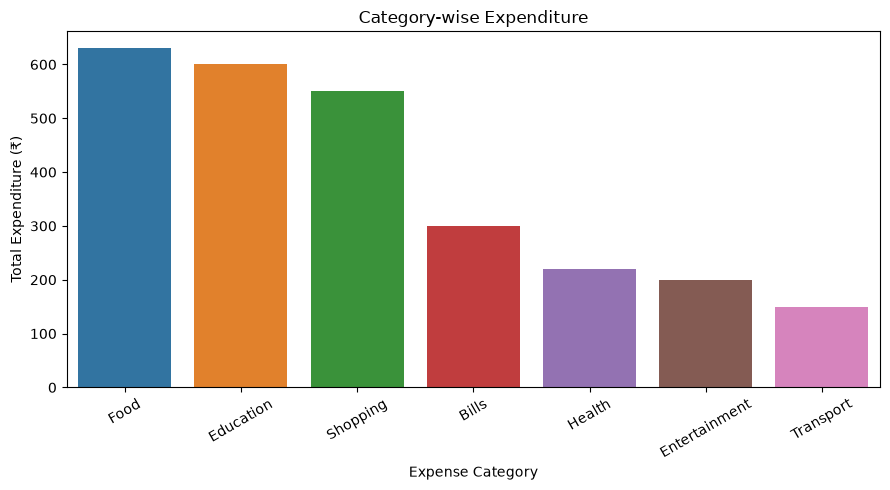

Saved: category_expenditure.png


In [10]:

# Chart 1: Category-wise Expenditure

if not category_summary.empty:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=category_summary,
        x="Category",
        y="Total_Expenditure",
        hue="Category",
        legend=False
    )

    plt.title("Category-wise Expenditure")
    plt.xlabel("Expense Category")
    plt.ylabel("Total Expenditure (₹)")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "category_expenditure.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print("Saved: category_expenditure.png")
else:
    print("No expense data available for the bar chart.")


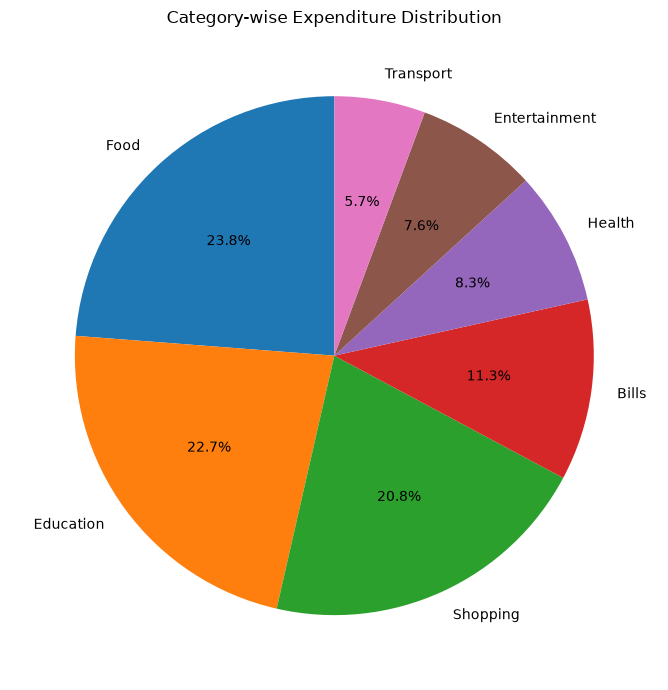

Saved: category_distribution.png


In [11]:

# Chart 2: Category-wise Expenditure Distribution

if not category_summary.empty:
    plt.figure(figsize=(7, 7))

    plt.pie(
        category_summary["Total_Expenditure"],
        labels=category_summary["Category"],
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Category-wise Expenditure Distribution")
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "category_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print("Saved: category_distribution.png")
else:
    print("No expense data available for the pie chart.")


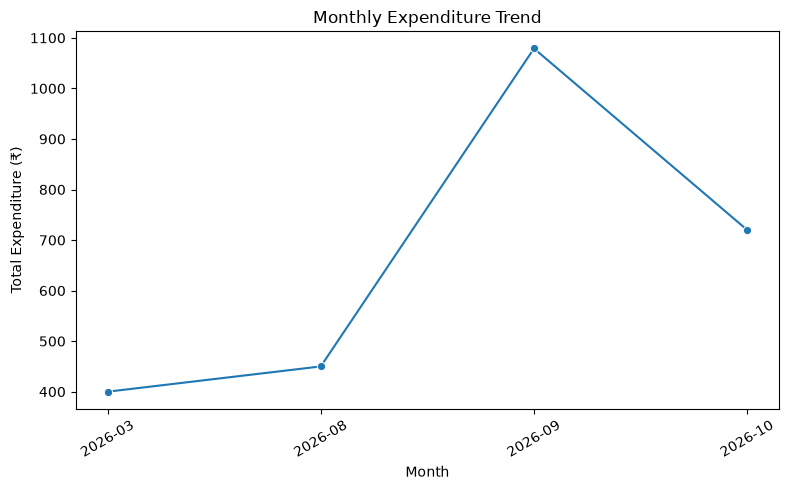

Saved: monthly_expenditure.png


In [12]:

# Chart 3: Monthly Expenditure Trend

if not monthly_summary.empty:
    plt.figure(figsize=(8, 5))

    sns.lineplot(
        data=monthly_summary,
        x="Month",
        y="Total_Expenditure",
        marker="o"
    )

    plt.title("Monthly Expenditure Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Expenditure (₹)")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "monthly_expenditure.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print("Saved: monthly_expenditure.png")
else:
    print("No expense data available for the monthly chart.")


## 9. Results and Interpretation

The Expense Analyzer notebook loads and cleans the unified main dataset using Pandas, calculates descriptive statistics using NumPy, summarizes expenditure by category and month, and visualizes spending patterns.

### Key Results

- **Number of transactions:** 10
- **Total expenditure:** ?2,649
- **Average transaction amount:** ?264.90
- **Highest-spending category:** Food, ?630
- **Shopping expenditure:** ?550
- **Highest monthly expenditure:** September 2026, ?1,079
- **Date range:** 20 March 2026 to 18 October 2026
- **Categories represented:** 7

The category-wise bar chart and pie chart compare expenditure across the seven recorded categories. Food accounts for approximately 23.8% of the total, while Shopping accounts for approximately 20.8%. The monthly trend chart shows expenditure across March, August, September, and October 2026.

These findings describe the 10 transactions currently recorded in the main project dataset.

## 10. Limitations

1. The dataset contains only 10 transactions, which is insufficient to establish reliable long-term spending habits.
2. The records span four calendar months with gaps between them, so they do not provide continuous month-to-month coverage.
3. The analysis depends on the accuracy and completeness of the recorded transactions.
4. This notebook reads the main CSV for analysis. The separate terminal application and Flask dashboard use SQLite for expense persistence.

## 11. Conclusion

The Expense Analyzer demonstrates how Python can organize, validate, and analyze personal expense data. Pandas supports data cleaning, grouping, and summarization, while NumPy performs numerical calculations. Matplotlib and Seaborn present the results through visualizations.

The wider project combines notebook-based analysis with a terminal expense manager, SQLite persistence, monthly budgeting, a Flask dashboard, and report generation. The current 10-record dataset provides a consistent basis for demonstrating and testing the project's analytical features.


## 12. Unified Dataset Verification

The notebook uses the main project file, `expenses.csv`, as its primary dataset. The following cell verifies the cleaned records, unique transaction IDs, valid dates, positive amounts, and expected total expenditure.

The separate `data/sample_expenses.csv` file is retained as an auxiliary file, but it is not used for the main analysis or these results.


In [13]:
# Verify the unified main dataset
unified_df = df_clean.copy()

assert len(unified_df) == 10, "Expected exactly 10 main-dataset records."
assert unified_df["ID"].is_unique, "Duplicate transaction IDs detected."
assert unified_df["Date"].notna().all(), "Invalid dates detected."
assert unified_df["Amount"].gt(0).all(), "Invalid or non-positive amounts detected."
assert np.isclose(
    np.sum(unified_df["Amount"].to_numpy(dtype=float)),
    2649.0
), "Main-dataset total does not match ?2,649."

print("UNIFIED MAIN DATASET VALIDATION")
print("-" * 40)
print("Source file:", EXPENSE_FILE.resolve())
print("Number of records:", len(unified_df))
print("Unique categories:", unified_df["Category"].nunique())
print("Missing values:", int(unified_df.isnull().sum().sum()))
print(f"Total expenditure: ?{unified_df['Amount'].sum():,.2f}")
print("Date range:",
      unified_df["Date"].min().date(), "to",
      unified_df["Date"].max().date())
print("\nAll validation checks passed.")

unified_monthly = (
    unified_df.assign(
        Month=unified_df["Date"].dt.to_period("M").astype(str)
    )
    .groupby("Month")["Amount"]
    .sum()
    .rename("Total Expenditure")
)

print("\nMONTHLY EXPENDITURE")
display(unified_monthly.to_frame())

print("\nUNIFIED MAIN TRANSACTIONS")
display(unified_df)


UNIFIED MAIN DATASET VALIDATION
----------------------------------------
Source file: C:\Users\santh\OneDrive\Desktop\ExpenseAnalyzer\expenses.csv
Number of records: 10
Unique categories: 7
Missing values: 0
Total expenditure: ?2,649.00
Date range: 2026-03-20 to 2026-10-18

All validation checks passed.

MONTHLY EXPENDITURE


,Total Expenditure
Month,
2026-03,400.0
2026-08,450.0
2026-09,1079.0
2026-10,720.0



UNIFIED MAIN TRANSACTIONS


,ID,Date,Category,Description,Amount
0,1,2026-03-20,Food,Icecream,100.0
1,2,2026-03-21,Shopping,clothes,300.0
2,3,2026-08-09,Shopping,Notebook and pens,250.0
3,4,2026-08-15,Entertainment,Movie ticket,200.0
4,5,2026-09-03,Food,Lunch,180.0
5,6,2026-09-07,Education,Study materials,600.0
6,7,2026-09-14,Bills,Mobile recharge,299.0
7,8,2026-10-02,Transport,Auto fare,150.0
8,9,2026-10-10,Food,Dinner,350.0
9,10,2026-10-18,Health,First aid supplies,220.0
